<a href="https://colab.research.google.com/github/ImDabAss28/Optical-disorder-effects/blob/main/KPM2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install "https://github.com/conda-incubator/condacolab/archive/main.zip"

import condacolab

condacolab.install(
    python_version="3.12",
    dependencies={
        "kwant": "*",
        "numpy": "*",
        "scipy": "*",
        "matplotlib": "*"
    }
)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
📝 Writing pixi.toml...
📦 Installing...
✨ Last touches...
⏲ Done in 0:00:49
✅ Done! Restarting kernel...
ℹ️ [INFO]
  Once the session reconnects, you will be running a new Python v3.12.
  You can install new packages by running pixi in new cells like this:
    !pixi add <name>


In [27]:
import kwant
import numpy as np
import scipy
import matplotlib.pyplot as plt
kwant.plotter.set_engine('matplotlib')

In [ ]:
def dos_kernel_polynomial(H, syst):

    R = 5

    Emax, _  = scipy.sparse.linalg.eigsh(H, k=1, which='LA', return_eigenvectors=True)
    Emin, _  = scipy.sparse.linalg.eigsh(H, k=1, which='SA', return_eigenvectors=True)

    corr = 1/R

    a = (Emax - Emin)/(2 - corr)
    b = (Emax + Emin)/2

    H_Tilde = (H - b*np.identity(H.shape[0])) / a

    #print(Emax, Emin)
    #chebyshev basis

    def Cheb_moment(r, H, n):
        T0 = r
        T1 = H @ r

        mu = np.zeros(n)

        mu[0] = np.vdot(r, T0).real

        if(n > 1):
            mu[1] = np.vdot(r,T1).real

        for i in range(2, n):
            Tn = 2 * (H @ T1) - T0
            mu[i] = np.vdot(r, Tn).real
            T0 = T1
            T1 = Tn

        return mu

    def kernel_jackson(D):
        n = np.arange(D)
        return ((D - n + 1) * np.cos(np.pi * n /(D + 1))+ np.sin(np.pi * n / (D + 1)) / np.tan(np.pi /(D + 1))) / (D + 1)

    #random vectors

    D = syst.graph.num_nodes * 2

    Trace = 0

    B = np.identity(D)
    moments = np.zeros(D)

    #print(B.shape)
    for i in range(R):
        E = np.random.normal(size = D) * np.pi
        r = np.dot(B, np.array((np.cos(E) + np.sin(E)*1j)))
        moments += Cheb_moment(r, H_Tilde, D)

    moments = kernel_jackson(D) * moments / R



    nE = 8 * D

    E_ = np.linspace(Emin, Emax, nE).ravel()
    X_ = ((E_ - b) / a).ravel()
    X_ = np.clip(X_, -1 + 1e-12, 1 - 1e-12)

    dos = np.zeros_like(X_)
    n = len(moments)
    for i in range(n - 3):
        dos += moments[i] * np.cos(i * np.arccos(X_))

    dos = dos/(np.pi * np.sqrt(1 - X_**2))

    dos = np.abs(dos)
    return X_ , dos
    #print(np.trace(H))
    #print(moments)

In [ ]:
import scipy as sp

def random_vec(len):
    v = np.random.normal(size = len) + np.random.normal(size = len) * 1j
    norm = np.linalg.norm(v)

    return v / norm

def chebyshev_values(x, n):
    T = [1, x]

    for i in range(1, n):
        T_next = 2*x*T[i] - T[i-1]
        T.append(T_next)

    return T

def chebyshev_cosine(x, n):
    return np.cos(n * np.arccos(x))


def fermi(x):

    B = 10
    E0 = 0
    return 1  / (np.exp((x - E0)*B) + 1)

def alpha_n_integral(n, a = 100):

  if n == 0:
      dn = 1.0
  else:
      dn = 2.0

  dx = 2.0 / a
  x = -1.0 + (np.arange(a) + 0.5) * dx



  alpha_vec = dn * chebyshev_cosine(-x, n) * fermi((x)) / (np.pi * np.sqrt(1 - x**2))
  return alpha_vec

def beta_n_integral(n, a = 100):

  if n == 0:
      dn = 1.0
  else:
      dn = 2.0


  dx = 2.0 / a
  x = -1.0 + (np.arange(a) + 0.5) * dx

  alpha_vec = dn * chebyshev_cosine(x, n) * fermi(x) / (np.pi * np.sqrt(1 - x**2))
  return alpha_vec

def convolve_ab(n, m, omega, a_points=2048):
  dx = 2.0 / a_points
  x = -1.0 + (np.arange(a_points) + 0.5) * dx

  alpha = alpha_n_integral(n, a=a_points)
  beta = beta_n_integral(m, a=a_points)

  gamma = signal.fftconvolve(
      alpha, beta, mode="full"
  ) * dx

  # Energy coordinates of the full convolution
  x_conv = 2.0 * x[0] + np.arange(2 * a_points - 1) * dx

  return np.interp(
      -omega, x_conv, gamma, left=0.0, right=0.0
  )

def jackson_kernel(N, n):
    theta = np.pi * n / (N + 1)
    return (
        (N - n + 1) * np.cos(theta)
        + np.sin(theta) / np.tan(np.pi / (N + 1))
    ) / (N + 1)

def kernel_polynomial_2_optical(H, syst, V, omega, n=20, norbs=1, R=10):

    Emax = spla.eigsh(
        H, k=1, which="LA", return_eigenvectors=False
    ).item()

    Emin = spla.eigsh(
        H, k=1, which="SA", return_eigenvectors=False
    ).item()
    corr = 1/R

    a = (Emax - Emin)/(2 - corr)
    b = (Emax + Emin)/2

    D = syst.graph.num_nodes * norbs

    I = sp.eye(H.shape[0], format="csr", dtype=H.dtype)

    H_Tilde = (H - b*I) / a

    full_sum = 0

    conv_matrix = {}

    for i in range(n + 1):
        for j in range(n + 1):
            conv_matrix[(i, j)] = convolve_ab(i, j, omega = omega)

    for vecs_iter in range(R):
        #T(x)
        #approximate with T = 0


        #T(H)
        r = random_vec(D)
        r_L = V @ r
        T0_R = r
        T1_R = H_Tilde @ r
        sum = 0

        T0_L = r_L
        T1_L = H_Tilde @ r_L

        L_moments = [T0_L]
        R_moments = [T0_R]

        for i in range(n):

            R_moments.append(T1_R)
            temp = T1_R
            T1_R = 2* (H_Tilde @ T1_R) - T0_R
            T0_R = temp

        for i in range(n):
            L_moments.append(T1_L)

            temp = T1_L
            T1_L = 2* (H_Tilde @ T1_L) - T0_L
            T0_L = temp


        for i in range(n + 1):
            for j in range(n + 1):
                sum += conv_matrix[(i, j)] * np.vdot(L_moments[j], V @ R_moments[i]) * jackson_kernel(n, i) * jackson_kernel(n, j)

        full_sum += sum


    return full_sum / R, Emax, Emin





In [ ]:
#pauli matrices

sigma_x = np.array([[0, 1], [1, 0]])
sigma_y = np.array([[0, -1j], [1j, 0]])
sigma_z = np.array([[1, 0], [0, -1]])

In [ ]:
dE_ = []
x_ = []
curr_ = []

R = 10
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.signal as signal

def current_x_matrix(H, syst, norbs=2):
    x = np.repeat(
        [site.pos[0] for site in syst.sites],
        norbs
    )

    X = sp.diags(x, format="csr")

    Jx = 1j * (H @ X - X @ H)

    return Jx.tocsr()


def onsite(site, mu, perturb):
    # get the position of the site
    x, y = site.pos
    return mu * sigma_z + perturb * sigma_x

rng = np.random.default_rng(seed = 40)

disorder = {}

def hopping(site1, site2, t0, tr):
    key = (tuple(site1.tag), tuple(site2.tag))

    if key not in disorder:
        uniform = rng.uniform(-1, 1, size=(2, 2))
        j_uniform = rng.uniform(-1, 1, size=(2, 2))
        disorder[key] = uniform + 1j * j_uniform

    return -t0 * sigma_z + tr * disorder[key]

def shape(site):
    x, y, = site.pos

    return x*x + y*y < R*R

template = kwant.Builder(kwant.TranslationalSymmetry(*np.identity(2)))

lat = kwant.lattice.square(norbs = 2)

template[lat(0,0)] = onsite

template[lat(0, 0), lat(0,1)] = hopping
template[lat(0, 0), lat(1,0)] = hopping
print(type(lat(0, 0)))

syst = kwant.Builder()
syst.fill(template, shape, (0,0));

Bloch = kwant.wraparound.wraparound(template, keep = None)
Bloch = Bloch.finalized()

syst = syst.finalized()

mu = 4
t0 = 0.5
tr = 1


perturb = 1

H_0 = syst.hamiltonian_submatrix(
    params={"mu": mu, "t0": t0, "tr": 0.0, "perturb": 0.0},
    sparse=True
).tocsr()

H_total = syst.hamiltonian_submatrix(
    params={"mu": mu, "t0": t0, "tr": 0.0, "perturb": perturb},
    sparse=True
).tocsr()

H_rand = syst.hamiltonian_submatrix(
    params={"mu": mu, "t0": t0, "tr": tr, "perturb": 0.0},
    sparse=True
).tocsr()

epsilon_x = 0.1

num_sites = syst.graph.num_nodes

J_total = current_x_matrix(H_total, syst)
J_0 = current_x_matrix(H_0, syst)

w = np.linspace((-2 + 1e-12), 2 - 1e-12, 1001)

R_avg = 100

opt_0, Emax_1, Emin_1 = kernel_polynomial_2_optical(H_0, syst, J_0, omega = w ,n = 20, norbs = 2, R = R_avg)
opt, Emax_2, Emin_2 = kernel_polynomial_2_optical(H_total, syst, J_total, omega = w, n = 20, norbs = 2, R = R_avg)
opt_rand, Emax_3, Emin_3 = kernel_polynomial_2_optical(H_rand, syst, J_total, omega = w, n = 20, norbs = 2, R = R_avg)

B = 10


#this makes it f(Ei) - f(Ej)
thermal_factor = -np.expm1(-B * w)




<class 'kwant.builder.Site'>


In [ ]:
H_rand = syst.hamiltonian_submatrix(
    params={"mu": mu, "t0": t0, "tr": tr, "perturb": 0.0},
    sparse=True
).tocsr()
opt_rand, Emax_3, Emin_3 = kernel_polynomial_2_optical(H_rand, syst, J_total, omega = w, n = 50, norbs = 2, R = R_avg)
opt_rand = opt_rand * thermal_factor

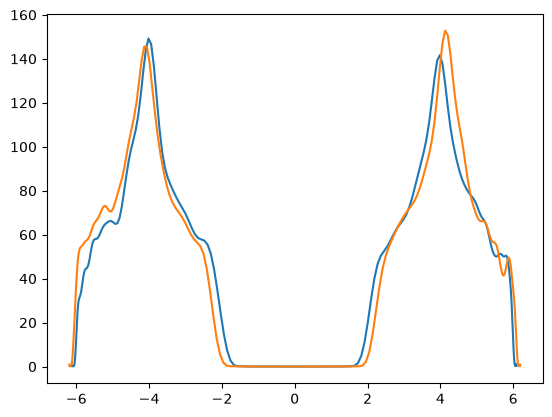

In [ ]:
spectrum = kwant.kpm.SpectralDensity(syst, params={"mu": mu, "t0": t0, "tr": 0.0, "perturb": 0.0})
energies, densities = spectrum()
plt.plot(energies, densities)
spectrum = kwant.kpm.SpectralDensity(syst, params={"mu": mu, "t0": t0, "tr": 0.0, "perturb": perturb})
energies, densities = spectrum()
plt.plot(energies, densities)

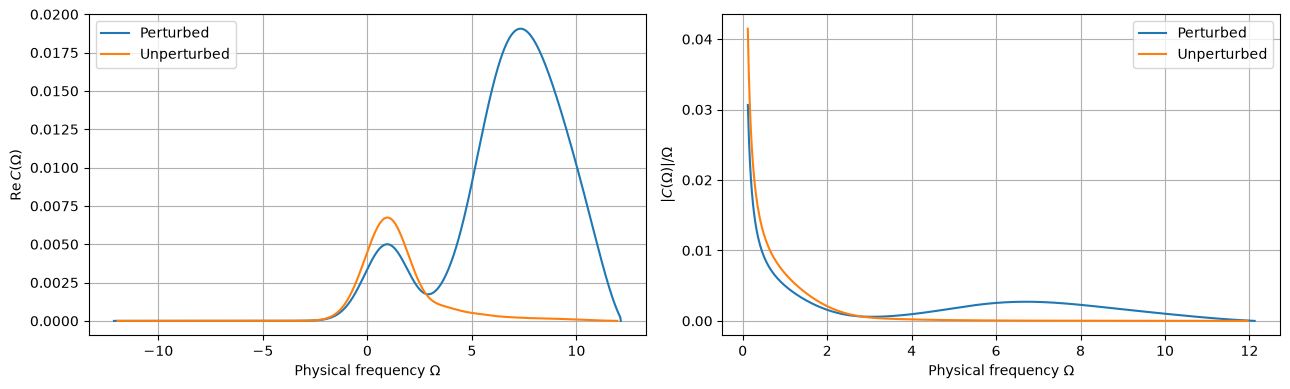

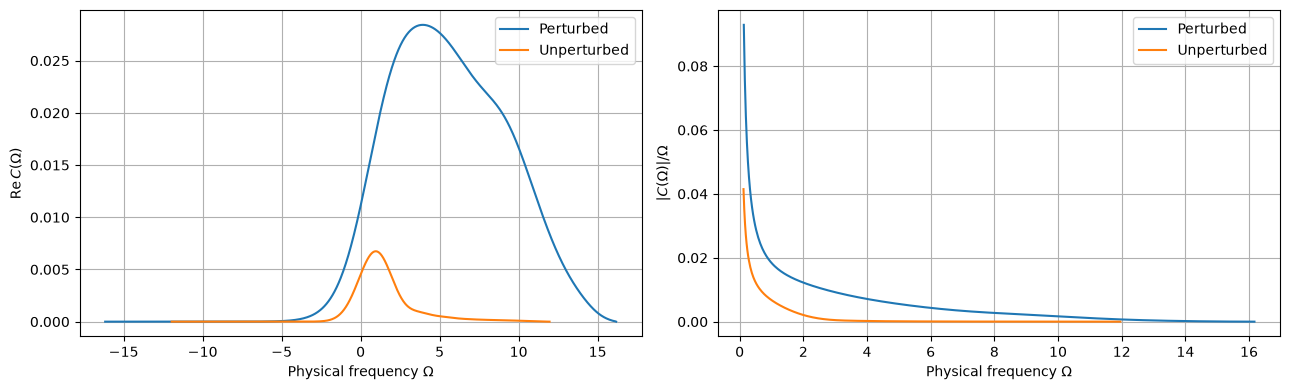

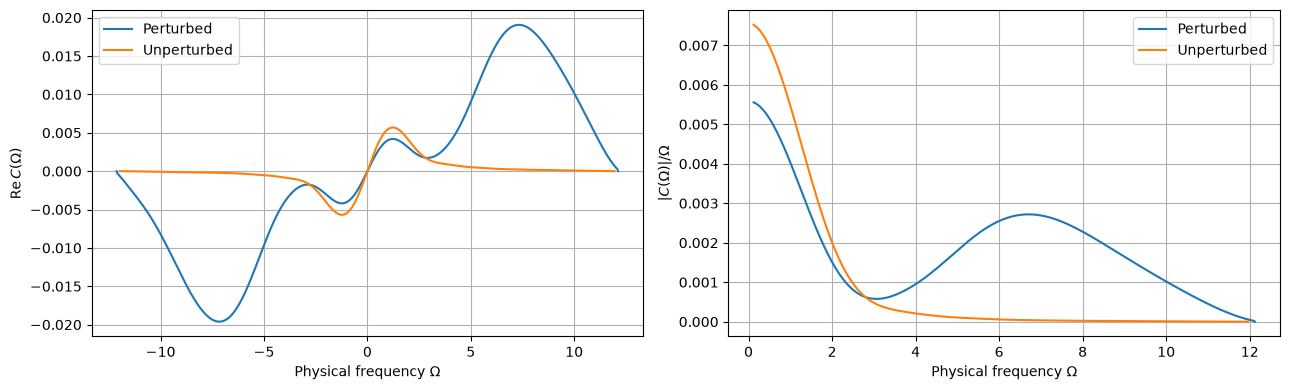

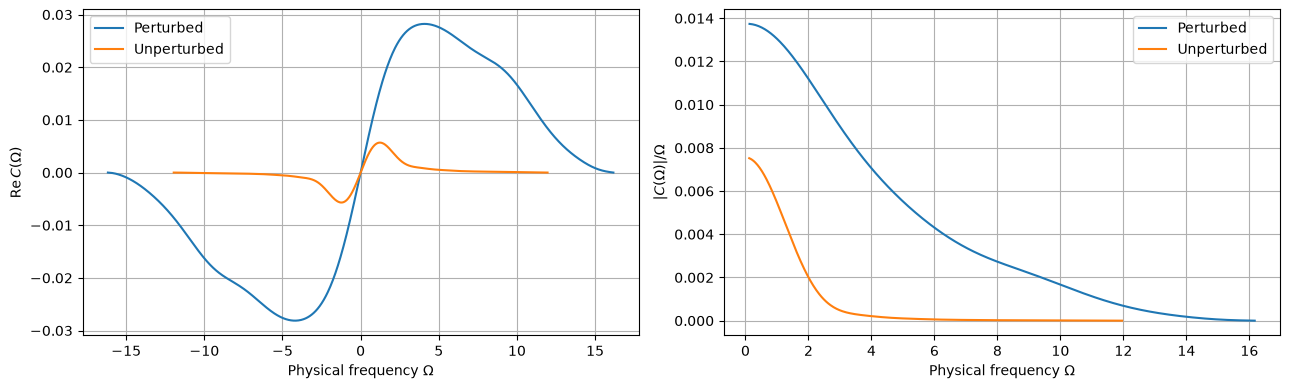

In [ ]:
def plot_optical_comparison(opt, opt_0, Emax, Emin, Emax_0, Emin_0,
                            R_avg=500, cutoff=0.1):

    a = (Emax - Emin) / (2 - 1 / R_avg)
    a_0 = (Emax_0 - Emin_0) / (2 - 1 / R_avg)

    omega = w * a
    omega_0 = w * a_0

    mask = omega > cutoff
    mask_0 = omega_0 > cutoff

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))

    ax[0].plot(omega, np.real(opt), label="Perturbed")
    ax[0].plot(omega_0, np.real(opt_0), label="Unperturbed")
    ax[0].set_xlabel(r"Physical frequency $\Omega$")
    ax[0].set_ylabel(r"$\mathrm{Re}\,C(\Omega)$")
    ax[0].legend()
    ax[0].grid()

    ax[1].plot(omega[mask], np.real(opt[mask]) / omega[mask],
               label="Perturbed")
    ax[1].plot(omega_0[mask_0], np.real(opt_0[mask_0]) / omega_0[mask_0],
               label="Unperturbed")
    ax[1].set_xlabel(r"Physical frequency $\Omega$")
    ax[1].set_ylabel(r"$|C(\Omega)|/\Omega$")
    ax[1].legend()
    ax[1].grid()

    plt.tight_layout()
    plt.show()

plot_optical_comparison(
    opt, opt_0,
    Emax_2, Emin_2,
    Emax_1, Emin_1
)
plot_optical_comparison(
    opt_rand, opt_0,
    Emax_3, Emin_3,
    Emax_1, Emin_1
)
opt = opt * thermal_factor
opt_0 = opt_0 * thermal_factor
opt_rand = opt_rand * thermal_factor

plot_optical_comparison(
    opt, opt_0,
    Emax_2, Emin_2,
    Emax_1, Emin_1
)
plot_optical_comparison(
    opt_rand, opt_0,
    Emax_3, Emin_3,
    Emax_1, Emin_1
)

diamond lattice

In [ ]:
dE_ = []
x_ = []
curr_ = []

R = 4

def current_x_matrix(H, syst, norbs=2):
    x = np.repeat(
        [site.pos[0] for site in syst.sites],
        norbs
    )

    X = sp.diags(x, format="csr")

    Jx = 1j * (H @ X - X @ H)

    return Jx.tocsr()

def onsite(site, perturb,  mu):
    return mu * sigma_z + perturb * sigma_x


def hopping(site1, site2, t0, t1, tr):
    #print(np.linalg.norm(site1.pos - site2.pos))
    key = (tuple(site1.tag), tuple(site2.tag))

    if key not in disorder:
        uniform = rng.uniform(-1, 1, size=(2, 2))
        j_uniform = rng.uniform(-1, 1, size=(2, 2))
        disorder[key] = uniform + 1j * j_uniform


    return t0 * sigma_z + t1 * sigma_y + tr * disorder[key] #np.array([[t0, -t1 * 1j],[t1 * 1j,-t0]]) + np.array([[t0, t1],[ -t1, -t0]])



def shape(site):

    x, y, z, = site.pos

    return x*x < R*R and y*y < R*R and z*z < R*R

vecs = 0.5 * np.array(((0, 1, 1), (1, 0, 1), (1, 1, 0)))

template = kwant.Builder(kwant.TranslationalSymmetry(*vecs))

lat = kwant.lattice.general(prim_vecs= vecs, basis=((0, 0, 0),(0.25, 0.25, 0.25)), norbs= 2)

a1, a2 = lat.sublattices


template[a1(0,0,0)] = onsite
template[a2(0,0,0)] = onsite

template[kwant.builder.HoppingKind((0, 0, 0), a1, a2)] = hopping
template[kwant.builder.HoppingKind((1, 0, 0), a1, a2)] = hopping
template[kwant.builder.HoppingKind((0, 1, 0), a1, a2)] = hopping
template[kwant.builder.HoppingKind((0, 0, 1), a1, a2)] = hopping


#print(a1.canonical_repr, a2)
syst = kwant.Builder()


syst.fill(template, shape, (0,0,0));

Bloch = kwant.wraparound.wraparound(template, keep = None)
Bloch = Bloch.finalized()

syst = syst.finalized()

mu = 4
t0 = 2
t1 = 0,1
tr = 0.2

perturb = 2

H_0 = syst.hamiltonian_submatrix(
    params={"mu": mu, "t0": t0, "t1" : t1, "tr": 0.0, "perturb": 0.0},
    sparse=True
).tocsr()

H_total = syst.hamiltonian_submatrix(
    params={"mu": mu, "t0": t0, "t1" : t1, "tr": 0.0, "perturb": perturb},
    sparse=True
).tocsr()

H_rand = syst.hamiltonian_submatrix(
    params={"mu": mu, "t0": t0, "t1" : t1, "tr": tr, "perturb": 0.0},
    sparse=True
).tocsr()

epsilon_x = 0.1

num_sites = syst.graph.num_nodes

J_total = current_x_matrix(H_total, syst)
J_0 = current_x_matrix(H_0, syst)

w = np.linspace((-2 + 1e-12), 2 - 1e-12, 2001)

R_avg = 100

opt_0, Emax_1, Emin_1 = kernel_polynomial_2_optical(H_0, syst, J_0, omega = w ,n = 20, norbs = 2, R = R_avg)
opt, Emax_2, Emin_2 = kernel_polynomial_2_optical(H_total, syst, J_total, omega = w, n = 20, norbs = 2, R = R_avg)
opt_rand, Emax_3, Emin_3 = kernel_polynomial_2_optical(H_rand, syst, J_total, omega = w, n = 20, norbs = 2, R = R_avg)




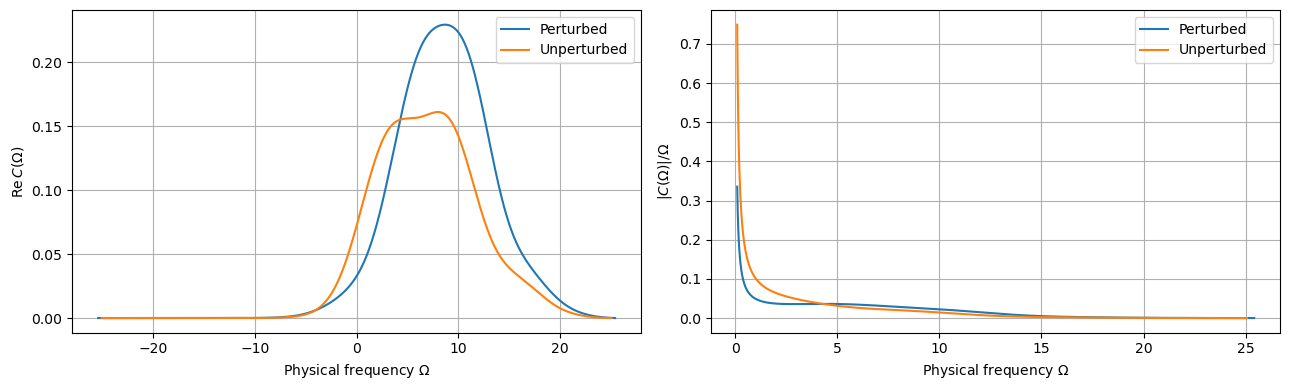

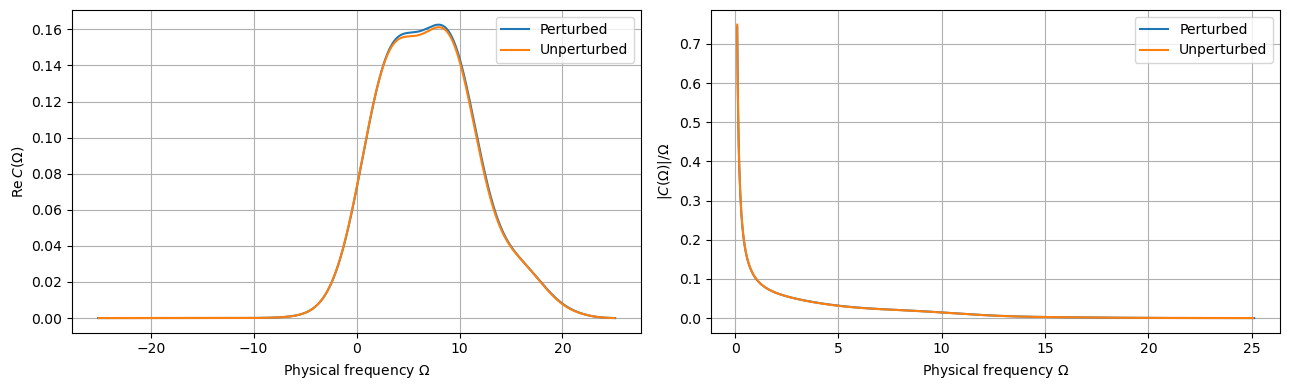

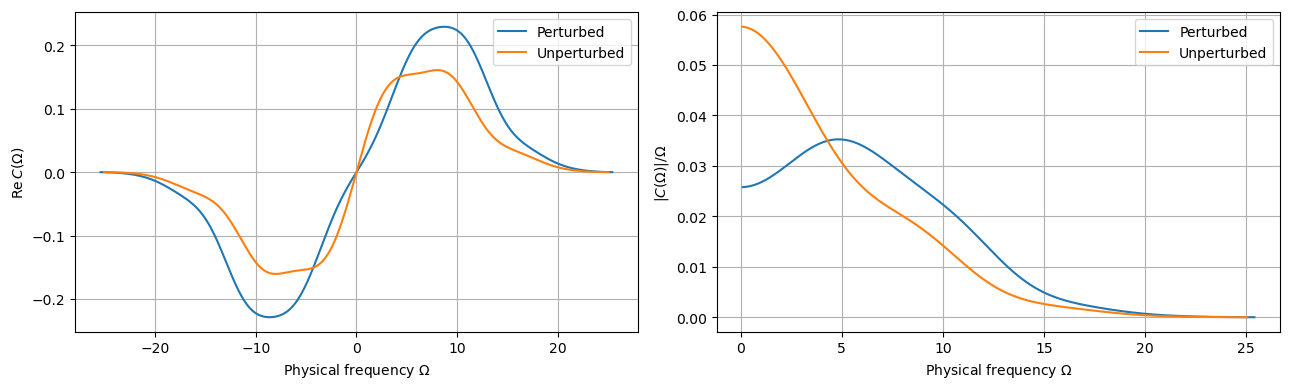

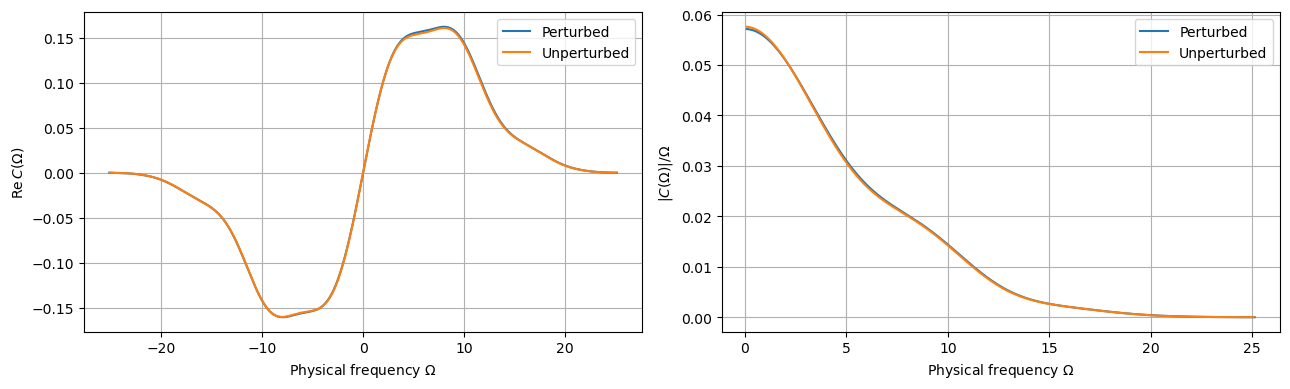

In [ ]:
plot_optical_comparison(
    opt, opt_0,
    Emax_2, Emin_2,
    Emax_1, Emin_1
)
plot_optical_comparison(
    opt_rand, opt_0,
    Emax_3, Emin_3,
    Emax_1, Emin_1
)

B = 10

thermal_factor = -np.expm1(-B * w)


opt = opt * thermal_factor
opt_0 = opt_0 * thermal_factor
opt_rand = opt_rand * thermal_factor
plot_optical_comparison(
    opt, opt_0,
    Emax_2, Emin_2,
    Emax_1, Emin_1
)
plot_optical_comparison(
    opt_rand, opt_0,
    Emax_3, Emin_3,
    Emax_1, Emin_1
)


Emax: 11.592026837721729
Emin: -11.533728258699593
Rescaled Hamiltonian shape: (138, 138)
Hilbert space dimension: 138


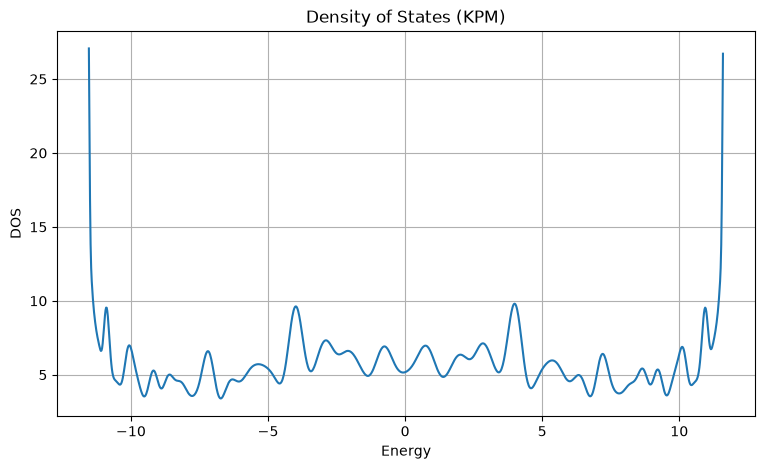

Trace of H: 0j
First 10 moments: [138.           0.40200461 -77.74825435   0.14257654  17.58049797
  -1.22323558   0.65838326   0.78622842  -9.32297567  -0.3824932 ]


In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

H_0 = syst.hamiltonian_submatrix(
    params={"mu": 4, "t0": 2, "t1" : 2, "tr": 0.1, "perturb": 0.0},
    sparse=True
).tocsr()


R = 100

Emax = spla.eigsh(
    H_0, k=1, which="LA", return_eigenvectors=False
).item()

Emin = spla.eigsh(
    H_0, k=1, which="SA", return_eigenvectors=False
).item()

corr = 0.01

a = (Emax - Emin) / (2 - corr)
b = (Emax + Emin) / 2

I = sp.eye(H_0.shape[0], format="csr", dtype=H_0.dtype)

H_Tilde = ((H_0 - b * I) / a).tocsr()

print("Emax:", Emax)
print("Emin:", Emin)
print("Rescaled Hamiltonian shape:", H_Tilde.shape)



def Cheb_moment(r, H, n):

    T0 = r
    T1 = H @ r

    mu = np.zeros(n)

    mu[0] = np.vdot(r, T0).real

    if n > 1:
        mu[1] = np.vdot(r, T1).real

    for i in range(2, n):

        Tn = 2 * (H @ T1) - T0

        mu[i] = np.vdot(r, Tn).real

        T0 = T1
        T1 = Tn

    return mu



def kernel_jackson(D):

    n = np.arange(D)

    return (
        (D - n + 1) * np.cos(np.pi * n / (D + 1))
        + np.sin(np.pi * n / (D + 1)) / np.tan(np.pi / (D + 1))
    ) / (D + 1)


D = H_0.shape[0]

moments = np.zeros(D)

print("Hilbert space dimension:", D)

for i in range(R):

    # Random phase vector
    theta = np.random.uniform(0, 2 * np.pi, size=D)

    r = np.exp(1j * theta)

    moments += Cheb_moment(r, H_Tilde, D)

moments /= R

# Apply Jackson kernel
moments *= kernel_jackson(D)

nE = 8 * D

E_ = np.linspace(Emin, Emax, nE)

X_ = (E_ - b) / a

X_ = np.clip(X_, -1 + 1e-12, 1 - 1e-12)

theta = np.arccos(X_)

dos = np.zeros_like(X_)

for i in range(D):

    dos += moments[i] * np.cos(i * theta)

dos /= np.pi * np.sqrt(1 - X_**2)

dos /= a

# Plot
plt.figure(figsize=(9, 5))
plt.plot(E_, dos)
plt.xlabel("Energy")
plt.ylabel("DOS")
plt.title("Density of States (KPM)")
plt.grid()
plt.show()

print("Trace of H:", H_0.diagonal().sum())
print("First 10 moments:", moments[:10])